# Pre-entrega 4 · Parte 3 — Benchmark contra el baseline del Módulo 3
**Data Science III · Módulo 4** — Elizabeth Luque

[![Abrir en Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/scarletluque0805/ds3-transformer-lora/blob/main/notebooks/04_parte3_benchmark.ipynb)

**Paso 5 de la práctica:** comparar contra el propio baseline, no contra un número abstracto.
- **Columna A:** TF-IDF (1,2) + Multinomial Naive Bayes, de la Pre-entrega 3.
- **Columna B:** `distilbert-base-uncased` + LoRA (r=8, α=16, Q-V), el adaptador entrenado en la Parte 2.

Mismo test para los dos: las 2.000 noticias de `ag_news_test.csv`, evaluadas **una sola vez**.

**Cómo correrlo:** `Entorno de ejecución → Cambiar tipo de entorno → T4 GPU` y después `Ejecutar todo`. Tarda unos 2 minutos. Al final se descarga `resultados_parte3.zip`.

## 0. Entorno

In [1]:
import os, sys, subprocess
from pathlib import Path
EN_COLAB = "google.colab" in sys.modules
if EN_COLAB:
    if not Path("/content/ds3-transformer-lora").exists():
        subprocess.run(["git", "clone", "-q", "https://github.com/scarletluque0805/ds3-transformer-lora.git", "/content/ds3-transformer-lora"], check=True)
    os.chdir("/content/ds3-transformer-lora")
    # Colab trae torchao 0.10 y peft exige >= 0.16: como no lo usamos, se desinstala antes de importar peft
    subprocess.run([sys.executable, "-m", "pip", "uninstall", "-y", "-q", "torchao"], check=False)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "peft", "datasets", "accelerate"], check=True)
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT)); sys.path.insert(0, str(ROOT / "data"))
print("Repositorio:", ROOT)

Repositorio: /content/ds3-transformer-lora


In [2]:
import json, time, warnings
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt, torch, transformers, peft
from transformers.utils import logging as hf_logging
hf_logging.set_verbosity_error()
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": .3})
pd.set_option("display.max_colwidth", 140)
GPU = torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU"
print(f"Dispositivo: {GPU} | torch {torch.__version__} | transformers {transformers.__version__} | peft {peft.__version__}")

Dispositivo: Tesla T4 | torch 2.14.1+cu130 | transformers 5.22.1 | peft 0.21.2


## 1. Datos, tokenizer y modelo con el adaptador de la Parte 2

In [3]:
from src import datos_hf as dh, entrenamiento as en, evaluacion as ev, modelos as mo
CONFIG = json.loads((ROOT / "reports/config_parte1.json").read_text())
CKPT, MAX_LEN = CONFIG["modelo_base"], CONFIG["max_length"]
tr, va, te, label2id, id2label = dh.preparar_dataframes()
ds = dh.a_datasetdict(tr, va, te)
from transformers import AutoTokenizer
tok = AutoTokenizer.from_pretrained(CKPT)
ds_tok = en.tokenizar(ds, tok, MAX_LEN)

DIR_ADAPTER = ROOT / "models/lora_distilbert_r8"
modelo = ev.cargar_con_adaptador(CKPT, DIR_ADAPTER, id2label, label2id)
print(f"Adaptador: {[f.name for f in DIR_ADAPTER.iterdir()]} ({sum(f.stat().st_size for f in DIR_ADAPTER.iterdir()) / 1e6:.1f} MB)")
print(f"Parámetros cargados desde el adaptador (LoRA + cabezal): {CONFIG['parametros']['entrenables']:,} de {CONFIG['parametros']['modelo_original']:,}")

config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

Map:   0%|          | 0/7200 [00:00<?, ? examples/s]

Map:   0%|          | 0/800 [00:00<?, ? examples/s]

Map:   0%|          | 0/2000 [00:00<?, ? examples/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

Adaptador: ['adapter_config.json', 'README.md', 'adapter_model.safetensors'] (3.0 MB)
Parámetros cargados desde el adaptador (LoRA + cabezal): 741,124 de 66,956,548


### Control de reproducibilidad: el adaptador recargado tiene que dar el mismo F1 de validación que en la Parte 2

In [4]:
resumen_p2 = pd.read_csv(ROOT / "reports/parte2/resumen_corridas.csv").set_index("corrida")
logits_va, _ = ev.predecir(modelo, ds_tok["validation"], tok)
f1_va = ev.metricas(va.labels.values, logits_va.argmax(1))["f1_macro"]
f1_p2 = resumen_p2.loc["principal", "val F1-macro (mejor)"]
print(f"F1-macro validación -> recargado: {f1_va:.4f} | Parte 2: {f1_p2:.4f} | diferencia: {abs(f1_va - f1_p2):.4f}")

F1-macro validación -> recargado: 0.9186 | Parte 2: 0.9186 | diferencia: 0.0000


## 2. Evaluación única en test

In [5]:
from sklearn.metrics import classification_report
logits_te, seg_inf = ev.predecir(modelo, ds_tok["test"], tok)
pred_lora = logits_te.argmax(1)
y = te.labels.values
nombres = [id2label[i] for i in range(4)]
print(f"Inferencia sobre {len(te):,} noticias: {seg_inf:.2f} s en {GPU} ({seg_inf / len(te) * 1000:.2f} ms por noticia)\n")
print(classification_report(y, pred_lora, target_names=nombres, digits=3))

Inferencia sobre 2,000 noticias: 1.95 s en Tesla T4 (0.98 ms por noticia)

              precision    recall  f1-score   support

    Business      0.794     0.900     0.843       500
    Sci_Tech      0.905     0.862     0.883       500
      Sports      0.974     0.972     0.973       500
       World      0.952     0.872     0.910       500

    accuracy                          0.901      2000
   macro avg      0.906     0.901     0.902      2000
weighted avg      0.906     0.901     0.902      2000



## 3. Benchmark: TF-IDF + Naive Bayes (Módulo 3) vs. DistilBERT + LoRA

In [6]:
base = json.loads((ROOT / "reports/baseline_modulo3.json").read_text())
pred_nb_txt = pd.read_csv(ROOT / "reports/baseline_predicciones_test.csv")
assert (pred_nb_txt.label.values == te.label.values).all(), "El test no coincide con el del baseline"
pred_nb = pred_nb_txt.pred_tfidf_nb.map(label2id).values

mA, mB = ev.metricas(y, pred_nb), ev.metricas(y, pred_lora)
bench = pd.DataFrame({"A · TF-IDF + Naive Bayes (M3)": mA, "B · DistilBERT + LoRA (M4)": mB}).T
bench = bench[["precision_macro", "recall_macro", "f1_macro", "f1_weighted", "accuracy"]]
bench.loc["Diferencia B − A (puntos)"] = (bench.iloc[1] - bench.iloc[0]) * 100
bench.round(4)

,precision_macro,recall_macro,f1_macro,f1_weighted,accuracy
A · TF-IDF + Naive Bayes (M3),0.8924,0.8920,0.8920,0.8920,0.8920
B · DistilBERT + LoRA (M4),0.9063,0.9015,0.9025,0.9025,0.9015
Diferencia B − A (puntos),1.3817,0.9500,1.0439,1.0439,0.9500


In [7]:
from sklearn.metrics import precision_recall_fscore_support as prfs
pA, rA, fA, _ = prfs(y, pred_nb, labels=range(4), zero_division=0)
pB, rB, fB, _ = prfs(y, pred_lora, labels=range(4), zero_division=0)
por_clase = pd.DataFrame({"Precision A": pA, "Precision B": pB, "Recall A": rA, "Recall B": rB, "F1 A": fA, "F1 B": fB}, index=nombres)
por_clase["Δ F1 (pts)"] = (por_clase["F1 B"] - por_clase["F1 A"]) * 100
por_clase.round(3)

,Precision A,Precision B,Recall A,Recall B,F1 A,F1 B,Δ F1 (pts)
Business,0.835,0.794,0.862,0.900,0.848,0.843,-0.494
Sci_Tech,0.870,0.905,0.870,0.862,0.870,0.883,1.320
Sports,0.955,0.974,0.968,0.972,0.961,0.973,1.170
World,0.910,0.952,0.868,0.872,0.888,0.910,2.180


In [8]:
# ¿La mejora es estadísticamente significativa? Test de McNemar sobre las noticias en que los modelos discrepan
ok_nb, ok_lora = pred_nb == y, pred_lora == y
mc = ev.mcnemar(ok_nb, ok_lora)
cont = pd.DataFrame([[int((ok_nb & ok_lora).sum()), mc["solo_acierta_A"]], [mc["solo_acierta_B"], int((~ok_nb & ~ok_lora).sum())]],
                    index=["LoRA acierta", "LoRA falla"], columns=["NB acierta", "NB falla"])
cont.loc["LoRA acierta", "NB acierta"], cont.loc["LoRA acierta", "NB falla"] = int((ok_nb & ok_lora).sum()), mc["solo_acierta_B"]
cont.loc["LoRA falla", "NB acierta"], cont.loc["LoRA falla", "NB falla"] = mc["solo_acierta_A"], int((~ok_nb & ~ok_lora).sum())
display(cont)
print(f"Solo acierta NB: {mc['solo_acierta_A']} | solo acierta LoRA: {mc['solo_acierta_B']} | p-valor McNemar exacto: {mc['p_valor']:.2e}")

,NB acierta,NB falla
LoRA acierta,1728,75
LoRA falla,56,141


Solo acierta NB: 56 | solo acierta LoRA: 75 | p-valor McNemar exacto: 1.15e-01


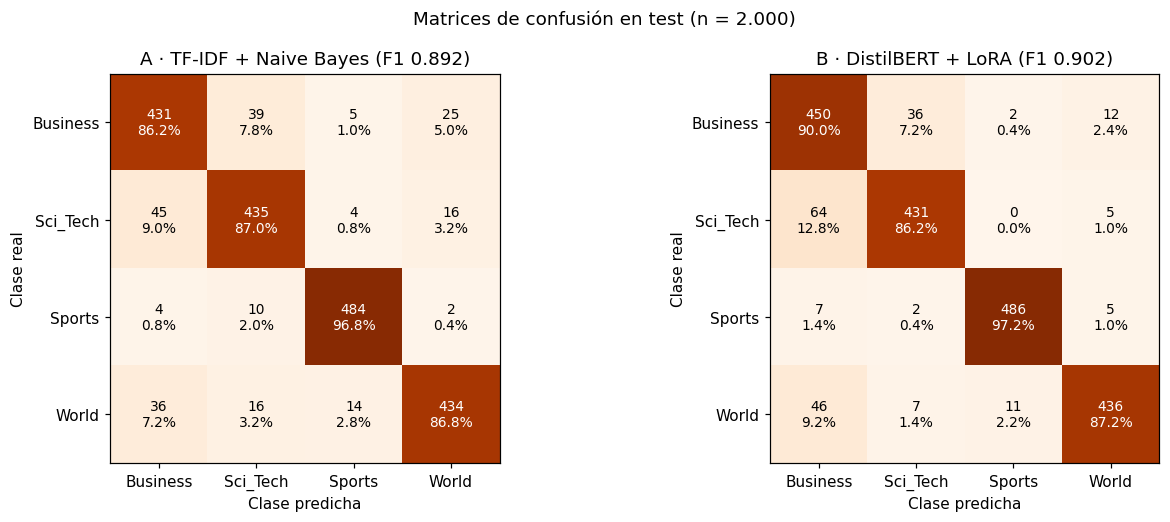

In [9]:
from sklearn.metrics import confusion_matrix
OUT = ROOT / "reports" / "parte3"; (OUT / "figures").mkdir(parents=True, exist_ok=True)
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.8))
for ax, pred, titulo in [(axes[0], pred_nb, f"A · TF-IDF + Naive Bayes (F1 {mA['f1_macro']:.3f})"),
                         (axes[1], pred_lora, f"B · DistilBERT + LoRA (F1 {mB['f1_macro']:.3f})")]:
    cm = confusion_matrix(y, pred, labels=range(4)); cmn = cm / cm.sum(1, keepdims=True)
    ax.imshow(cmn, cmap="Oranges", vmin=0, vmax=1)
    ax.set_xticks(range(4), nombres); ax.set_yticks(range(4), nombres); ax.grid(False)
    ax.set(xlabel="Clase predicha", ylabel="Clase real", title=titulo)
    for i in range(4):
        for j in range(4):
            ax.text(j, i, f"{cm[i, j]}\n{cmn[i, j]:.1%}", ha="center", va="center", fontsize=9, color="white" if cmn[i, j] > .5 else "black")
fig.suptitle("Matrices de confusión en test (n = 2.000)", fontsize=12)
fig.tight_layout(); fig.savefig(OUT / "figures/matrices_confusion_A_vs_B.png", dpi=150); plt.show()

In [10]:
# Pares de clases más confundidos: ¿dónde mejora el Transformer?
def pares(pred):
    cm = pd.DataFrame(confusion_matrix(y, pred, labels=range(4)), index=nombres, columns=nombres).stack()
    return cm[[a != b for a, b in cm.index]]
conf = pd.DataFrame({"errores A (NB)": pares(pred_nb), "errores B (LoRA)": pares(pred_lora)})
conf["reducción"] = conf["errores A (NB)"] - conf["errores B (LoRA)"]
conf.index.names = ["real", "predicha"]
conf.sort_values("errores A (NB)", ascending=False).head(8)

,,errores A (NB),errores B (LoRA),reducción
real,predicha,,,
Sci_Tech,Business,45,64,-19
Business,Sci_Tech,39,36,3
World,Business,36,46,-10
Business,World,25,12,13
World,Sci_Tech,16,7,9
Sci_Tech,World,16,5,11
World,Sports,14,11,3
Sports,Sci_Tech,10,2,8


In [11]:
# Ejemplos que el Transformer corrige (y que TF-IDF clasificaba mal)
ej = te.assign(NB=[id2label[i] for i in pred_nb], LoRA=[id2label[i] for i in pred_lora])
corrige = ej[~ok_nb & ok_lora]
corrige[["label", "NB", "LoRA", "text"]].assign(text=lambda d: d.text.str[:150]).groupby(["label", "NB"]).head(1).head(6)

,label,NB,LoRA,text
14,Business,World,Business,"EU, US Talks on Aircraft Aid Grounded. US and EU negotiators disagreed on Thursday about state aid for aircraft rivals Airbus and Boeing..."
105,Sci_Tech,World,Sci_Tech,"Barents Sea Under Threat from Fishing, Oil . The Arctic Barents Sea is under threat from overfishing, oil and gas exploration and Soviet..."
109,Sci_Tech,Business,Sci_Tech,Google Founders Selling Off Stock. Google Founders Selling Off Stock Is this a sign that Google stack is overpriced? Or does it just mea...
113,World,Business,World,"Coors' Donation to Own Campaign Draws Ire . A $500,000 donation by Republican beer baron Pete Coors to his own Senate campaign has trigg..."
149,Business,Sci_Tech,Business,"Med school move delayed to 2007. The MSU College of Human Medicine won 't be relocated to Grand Rapids until at least 2007, and could co..."
172,World,Sci_Tech,World,Analysis: Iran 's missile capabilities. Iran has announced it has improved its missile capabilities by developing a medium-range ballist...


In [12]:
# Errores que siguen en el Transformer
sigue = ej[~ok_lora]
sigue[["label", "NB", "LoRA", "text"]].assign(text=lambda d: d.text.str[:150]).groupby(["label", "LoRA"]).head(1).head(6)

,label,NB,LoRA,text
0,World,Business,Business,BSkyB sees profits rise after strong subscriber growth . British satellite broadcaster BSkyB said profit rose by 16 percent in the first...
19,World,Sports,Sports,"Maddux Wins No. 302, Baker Wins No. 1,000. Greg Maddux pitched the Chicago Cubs into the lead in the NL wild-card race and gave Dusty Ba..."
45,Sci_Tech,Business,Business,E.U. Regulators Approve Oracle's PeopleSoft Bid. European Union antitrust regulators on Tuesday cleared Oracle Corp.'s hostile $7.7 bill...
52,Sports,Sports,World,Tiger Woods Ties the Knot with Swedish Ex-Nanny. Former world number one Tiger Woods has married Swedish model Elin Nordegren at the lux...
79,World,World,Sci_Tech,"Early Voters Transform Campaign Landscape . In an election year when just a few thousand votes in a few states could decide the winner, ..."
87,Business,Business,Sci_Tech,"Clouds darken PeopleSoft conference. PeopleSoft Inc. is trying to create a party-like atmosphere at its annual customer conference, but ..."


## 4. Costo computacional vs. mejora

In [13]:
p2 = resumen_p2.loc["principal"]
tam_adapter = sum(f.stat().st_size for f in DIR_ADAPTER.iterdir()) / 1e6
costos = pd.DataFrame({
    "A · TF-IDF + NB (M3)": {"F1-macro test": round(mA["f1_macro"], 4), "hardware": "CPU",
                             "tiempo de entrenamiento": f"{base['tiempo_entrenamiento_seg']:.2f} s",
                             "parámetros entrenados": "103.120 (log-probabilidades)",
                             "inferencia 2.000 noticias": f"{base['inferencia_test_seg']['solo_modelo_cpu']:.2f} s (+{base['inferencia_test_seg']['con_preprocesamiento_spacy_cpu']:.1f} s spaCy)",
                             "almacenamiento": "≈1 MB"},
    "B · DistilBERT + LoRA (M4)": {"F1-macro test": round(mB["f1_macro"], 4), "hardware": GPU,
                                   "tiempo de entrenamiento": f"{p2['minutos'] * 60:.0f} s ({p2['minutos']} min, 4 épocas)",
                                   "parámetros entrenados": f"{CONFIG['parametros']['entrenables']:,} (1,11% de {CONFIG['parametros']['modelo_original'] / 1e6:.1f} M)",
                                   "inferencia 2.000 noticias": f"{seg_inf:.2f} s",
                                   "almacenamiento": f"{tam_adapter:.1f} MB adaptador + 268 MB modelo base"},
})
mejora = (mB["f1_macro"] - mA["f1_macro"]) * 100
err_A, err_B = int((~ok_nb).sum()), int((~ok_lora).sum())
print(f"Mejora: {mejora:+.2f} puntos de F1-macro | errores en test: {err_A} -> {err_B} ({(err_B - err_A) / err_A:+.0%})")
print(f"Entrenamiento: {p2['minutos'] * 60 / base['tiempo_entrenamiento_seg']:.0f}x más tiempo, y con GPU en vez de CPU")
costos

Mejora: +1.04 puntos de F1-macro | errores en test: 216 -> 197 (-9%)
Entrenamiento: 140x más tiempo, y con GPU en vez de CPU


,A · TF-IDF + NB (M3),B · DistilBERT + LoRA (M4)
F1-macro test,0.892,0.9025
hardware,CPU,Tesla T4
tiempo de entrenamiento,0.44 s,"62 s (1.03 min, 4 épocas)"
parámetros entrenados,103.120 (log-probabilidades),"741,124 (1,11% de 67.0 M)"
inferencia 2.000 noticias,0.09 s (+5.5 s spaCy),1.95 s
almacenamiento,≈1 MB,3.0 MB adaptador + 268 MB modelo base


## 5. Tabla esperado vs. observado

In [14]:
tabla = pd.DataFrame([
    ["Adaptador recargado = Parte 2", "F1 validación idéntico", f"{f1_va:.4f} vs {f1_p2:.4f}"],
    ["Mismo test que el baseline", "2.000 noticias, mismo orden", "OK"],
    ["Transformer supera al baseline", "F1-macro B > A", f"{mB['f1_macro']:.4f} vs {mA['f1_macro']:.4f} ({mejora:+.2f} pts)"],
    ["Mejora significativa", "p-valor McNemar < 0,05", f"{mc['p_valor']:.1e}"],
    ["Business ↔ Sci_Tech mejora", "menos errores en ese par", f"{int(conf.loc[('Business', 'Sci_Tech'), 'errores A (NB)'] + conf.loc[('Sci_Tech', 'Business'), 'errores A (NB)'])} -> {int(conf.loc[('Business', 'Sci_Tech'), 'errores B (LoRA)'] + conf.loc[('Sci_Tech', 'Business'), 'errores B (LoRA)'])}"],
    ["F1 macro = weighted", "iguales (clases balanceadas)", f"{mB['f1_macro']:.4f} / {mB['f1_weighted']:.4f}"],
], columns=["Prueba", "Esperado", "Observado"])
tabla

,Prueba,Esperado,Observado
0,Adaptador recargado = Parte 2,F1 validación idéntico,0.9186 vs 0.9186
1,Mismo test que el baseline,"2.000 noticias, mismo orden",OK
2,Transformer supera al baseline,F1-macro B > A,0.9025 vs 0.8920 (+1.04 pts)
3,Mejora significativa,"p-valor McNemar < 0,05",1.2e-01
4,Business ↔ Sci_Tech mejora,menos errores en ese par,84 -> 100
5,F1 macro = weighted,iguales (clases balanceadas),0.9025 / 0.9025


## 6. Guardar y descargar los resultados

In [15]:
resultados = {"gpu": GPU, "val_f1_recargado": f1_va, "test": {"A_tfidf_nb": mA, "B_distilbert_lora": mB},
              "por_clase": por_clase.round(4).to_dict(), "mcnemar": mc, "inferencia_test_seg": seg_inf,
              "errores_test": {"A": err_A, "B": err_B}}
(OUT / "metricas_parte3.json").write_text(json.dumps(resultados, indent=2, ensure_ascii=False, default=float))
pd.DataFrame({"idx": range(len(te)), "label": te.label, "pred_tfidf_nb": [id2label[i] for i in pred_nb],
              "pred_distilbert_lora": [id2label[i] for i in pred_lora],
              "proba_max_lora": torch.softmax(torch.tensor(logits_te), -1).max(-1).values.numpy().round(4)}).to_csv(OUT / "predicciones_test.csv", index=False)
bench.round(4).to_csv(OUT / "benchmark.csv"); por_clase.round(4).to_csv(OUT / "por_clase.csv"); costos.to_csv(OUT / "costos.csv")
conf.to_csv(OUT / "pares_confundidos.csv"); cont.to_csv(OUT / "mcnemar_contingencia.csv")
import zipfile
zip_path = "/content/resultados_parte3.zip" if EN_COLAB else str(ROOT / "resultados_parte3.zip")
with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as z:
    for f in OUT.rglob("*"):
        if f.is_file():
            z.write(f, f.relative_to(ROOT))
print("Generado:", zip_path)
if EN_COLAB:
    from google.colab import files
    files.download(zip_path)

Generado: /content/resultados_parte3.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>